# 04 · Temporada 2026: avaliação fora da amostra e simulação do fim do campeonato

Os jogos de 2026 vêm da minha planilha (`data/raw/jogos_2026.csv`, gerado por `scripts/importar_planilha.py`). Eles **não foram usados em nenhuma decisão** do modelo: os hiperparâmetros e a escolha do modelo final foram fixados antes, com 2020–2022. Por isso 2026 é um teste totalmente novo.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.width", 200)

# paleta categórica validada (daltonismo) + rampa sequencial azul
CORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
AZUL = LinearSegmentedColormap.from_list("azul", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8a85", "axes.labelcolor": "#3b3b38",
    "xtick.color": "#5c5c58", "ytick.color": "#5c5c58",
    "lines.linewidth": 2, "lines.markersize": 7, "figure.dpi": 110,
})

In [2]:
from brasileirao import load_all, build_features, walk_forward, summarize
from brasileirao.data import load_fixtures

raw = load_all()
jogados = raw[raw["temporada"] == 2026]
faltam = load_fixtures(2026)
print(f"2026: {len(jogados)} jogos disputados (até {jogados['data'].max():%d/%m/%Y}), {len(faltam)} a disputar")

2026: 339 jogos disputados (até 06/11/2026), 41 a disputar


## 1. Backtest rodada a rodada em 2026

Mesmo protocolo do notebook 03: antes de cada rodada, cada modelo é retreinado só com os jogos anteriores a ela.

In [3]:
df, _ = build_features(raw)
preds = walk_forward(df, temporadas=(2026,), verbose=False)
preds.to_csv("../results/previsoes_2026.csv", index=False)
ordem = list(preds["modelo"].unique())
res26 = summarize(preds).set_index("modelo").loc[ordem]
res26.round(4)

,jogos,log_loss,rps,brier,acuracia
modelo,,,,,
Baseline (frequência),339,1.0492,0.2177,0.6319,0.4867
Elo + regressão logística,339,1.0007,0.2018,0.5997,0.5221
Dixon-Coles (Poisson),339,1.0072,0.2025,0.6039,0.5280
Gradient Boosting (Elo + forma),339,0.9988,0.1996,0.5967,0.5280
Média (Dixon-Coles + Elo),339,1.0011,0.2014,0.5999,0.5192


In [4]:
from brasileirao.models import CLASSES

def rps_por_jogo(g):
    p = g[["p_H", "p_D", "p_A"]].to_numpy()
    y = np.array([CLASSES.index(r) for r in g["resultado"]])
    cp = np.cumsum(p, 1)[:, :2]; co = np.cumsum(np.eye(3)[y], 1)[:, :2]
    return np.sum((cp - co) ** 2, 1) / 2

base = preds[preds["modelo"] == "Baseline (frequência)"].reset_index(drop=True)
final = preds[preds["modelo"] == "Média (Dixon-Coles + Elo)"].reset_index(drop=True)
diff = rps_por_jogo(base) - rps_por_jogo(final)
por_rodada = pd.DataFrame({"rodada": final["rodada"], "diff": diff}).groupby("rodada")["diff"].agg(["sum", "size"])
rng = np.random.default_rng(0)
B = rng.integers(0, len(por_rodada), size=(2000, len(por_rodada)))
boot = por_rodada["sum"].to_numpy()[B].sum(1) / por_rodada["size"].to_numpy()[B].sum(1)
print(f"Modelo final: RPS {rps_por_jogo(final).mean():.4f} vs baseline {rps_por_jogo(base).mean():.4f}")
print(f"Ganho médio: {diff.mean():.4f}  (IC 95% bootstrap por rodada: {np.percentile(boot, 2.5):.4f} a {np.percentile(boot, 97.5):.4f})")

Modelo final: RPS 0.2014 vs baseline 0.2177
Ganho médio: 0.0163  (IC 95% bootstrap por rodada: 0.0067 a 0.0259)


## 2. Tabela atual

In [5]:
from brasileirao.simulacao import tabela, simular
tab = tabela(jogados)
tab

,pos,P,J,V,E,D,GP,GC,SG
time,,,,,,,,,
Flamengo,1,76,34,23,7,4,71,29,42
Palmeiras,2,73,34,21,10,3,62,23,39
Cruzeiro,3,60,34,18,6,10,55,48,7
Fluminense,4,57,34,16,9,9,55,42,13
Athletico-PR,5,54,34,15,9,10,51,43,8
Bahia,6,53,34,14,11,9,50,45,5
Atletico-MG,7,50,34,14,8,12,44,40,4
Bragantino,8,47,34,13,8,13,44,39,5
Santos,9,47,34,12,11,11,50,49,1


## 3. Próximos jogos

Previsões do modelo final, treinado com todos os jogos até agora.

In [6]:
from brasileirao.predictor import Previsor

prev = Previsor.treinar(raw)
prox = []
for r in faltam.itertuples(index=False):
    p = prev.prever(r.mandante, r.visitante)
    prox.append({"rodada": r.rodada, "data": f"{r.data:%d/%m}", "jogo": f"{r.mandante} x {r.visitante}",
                 "mandante": p["mandante"], "empate": p["empate"], "visitante": p["visitante"]})
prox = pd.DataFrame(prox)
(prox.set_index(["rodada", "data", "jogo"]) * 100).round(1).head(11)

mandante  empate  visitante
rodada data  jogo                                                  
21     14/11 Chapecoense x Vasco            30.8    26.7       42.5
35     14/11 Mirassol x Atletico-MG         46.1    28.0       25.9
       18/11 Coritiba x Santos              37.9    27.7       34.4
             Remo x Chapecoense             58.5    23.5       17.9
             Cruzeiro x Palmeiras           33.8    29.2       37.1
             Flamengo x Athletico-PR        71.3    18.8        9.9
             Gremio x Bahia                 41.0    27.9       31.1
             Corinthians x Botafogo-RJ      43.1    28.3       28.6
       19/11 Vitoria x Bragantino           37.5    29.3       33.2
             Vasco x Internacional          48.2    26.7       25.1
             Sao Paulo x Fluminense         38.2    29.6       32.2

## 4. Simulação do fim do campeonato

Cada jogo que falta é sorteado a partir da matriz de placares do Dixon-Coles, ajustada pras probabilidades do modelo final. Isso é repetido **20.000 vezes**. Os desempates seguem os critérios da CBF: pontos, vitórias, saldo de gols e gols marcados.

In [7]:
sim = simular(prev, jogados, faltam, n=20000, seed=0)
mostra = sim[["pos_atual", "pontos_atuais", "pontos_esperados"]].copy()
for c in ["campeao", "G4", "G6", "Z4"]:
    mostra[c + " (%)"] = (sim[c] * 100).round(1)
mostra.round(1)

,pos_atual,pontos_atuais,pontos_esperados,campeao (%),G4 (%),G6 (%),Z4 (%)
Flamengo,1,76,84.1,85.9,100.0,100.0,0.0
Palmeiras,2,73,80.8,14.1,100.0,100.0,0.0
Cruzeiro,3,60,66.3,0.0,97.9,100.0,0.0
Fluminense,4,57,63.0,0.0,79.2,99.5,0.0
Athletico-PR,5,54,59.4,0.0,12.3,86.9,0.0
Bahia,6,53,59.1,0.0,9.2,75.6,0.0
Atletico-MG,7,50,55.8,0.0,1.2,28.6,0.0
Santos,9,47,53.2,0.0,0.0,4.4,0.0
Bragantino,8,47,52.7,0.0,0.1,4.7,0.0
Sao Paulo,10,44,49.4,0.0,0.0,0.2,0.0


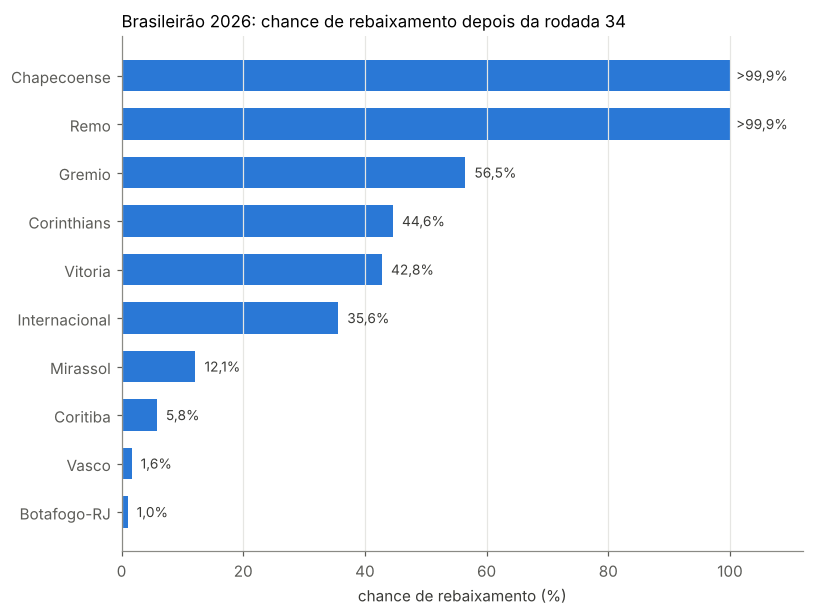

In [8]:
z4 = sim[sim["Z4"] > 0.005]["Z4"].sort_values()
fig, ax = plt.subplots(figsize=(7.5, 0.45 * len(z4) + 1.2))
ax.barh(z4.index, z4.values * 100, color=CORES[0], height=0.65)
for y, v in enumerate(z4.values):
    rot = ">99,9%" if v > 0.999 else f"{v*100:.1f}%".replace(".", ",")
    ax.text(min(v * 100 + 1.5, 101), y, rot, va="center", fontsize=9, color="#3b3b38")
ax.set_xlim(0, 112); ax.grid(axis="y", visible=False)
ax.set_xlabel("chance de rebaixamento (%)")
ax.set_title(f"Brasileirão 2026: chance de rebaixamento depois da rodada {int(jogados['rodada'].max())}", loc="left", fontsize=11)
plt.tight_layout(); plt.savefig("../results/rebaixamento_2026.png", dpi=150); plt.show()

### Limitações da simulação
- A força de cada time fica fixa até o fim. O modelo não se atualiza dentro de cada simulação.
- O modelo não sabe de lesões, suspensões, escalações alternativas nem de times que já não disputam nada.
- O placar de cada jogo é sorteado de forma independente dos outros.